# B3 — Huấn luyện Đối chứng (Ablation Baseline) & Vòng 1 (Run 1)

**Mục tiêu của Bước 3 (B3):**
1. **Phần A — Ablation Baseline (Run 0):** Huấn luyện trên 100% `train_pool.csv` (`24.628` mẫu, KHÔNG dùng pseudo-label) cho nhóm `ablation_preset` (mặc định `fast_3`: `Vi-ELECTRA`, `PhoBERT`, `ViSoBERT`; có thể đổi sang `full_7`) để tạo mốc đối chứng khoa học.
2. **Phần B — Run 1 (7 Seed Models):** Huấn luyện từng mô hình trong `model_preset` trên tập con riêng (`subsets/train_subset1..7.csv`, `10.000` mẫu/tập), tạo độ đa dạng giữa các mô hình trước khi bỏ phiếu Ensemble ở Bước B4.
3. **Chống rò rỉ dữ liệu & Chống quá tải RTX 5070:**
   - Chọn best checkpoint & Early Stopping **hoàn toàn trên `val.csv` (`2.737` mẫu)** theo `eval_f1_macro`.
   - Chỉ chấm điểm độc lập trên `test_clean.csv` (`3.000` mẫu) sau khi huấn luyện xong.
   - Dùng `bf16=True`, `train_batch_size=16 × accum=2`, `skip_if_done=True`, tự xóa checkpoint tạm và nghỉ tản nhiệt 15 giây giữa các mô hình.
4. **Biểu đồ xuất tại `workspace_outputs/figures/B3_baseline_run1/` (300 DPI `.png` + `.pdf`):**
   - `B3_01_learning_curves_run1` (và `B3_01b_learning_curves_baseline`)
   - `B3_02_so_sanh_hieu_nang_run1`

In [1]:
# Bước 3.1: Khởi tạo môi trường, công tắc linh hoạt & kiểm tra dữ liệu từ Bước B2
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PipelineConfig,
    ensure_directories,
    set_global_seed,
    get_figure_dir,
    PROCESSED_DATA_DIR,
    SUBSETS_DIR,
    CHECKPOINTS_DIR,
    METRICS_DIR,
    LABEL_NAMES,
)
from src.trainer import ESGTrainer
from src.evaluator import ESGEvaluator
from src.viz_utils import (
    plot_learning_curves_grid,
    plot_run_benchmark_comparison,
)

ensure_directories()

# ==================== CÔNG TẮC LINH HOẠT CHO BƯỚC B3 ====================
# - hardware_mode   : 'eco' (nhẹ/mát nhất) | 'balanced' (mặc định RTX 5070) | 'performance'
# - model_preset    : 'fast_3' (chạy thử nhanh) | 'vietnamese_4' | 'full_7' (đủ 7 mô hình)
# - ablation_preset : 'fast_3' (3 model VN đối chứng) | 'full_7' (đủ 7 model)
# - skip_if_done    : True -> ngắt giữa chừng chạy lại sẽ tự bỏ qua mô hình đã xong!
cfg = PipelineConfig(
    hardware_mode="balanced",
    model_preset="full_7",
    ablation_preset="fast_3",
    run_ablation_baseline=True,
    skip_if_done=True,
)
# ========================================================================

set_global_seed(cfg.seed)
FIG_DIR = get_figure_dir("B3")

print(cfg.summary())
print(f"\nNơi lưu biểu đồ Bước B3: {FIG_DIR}")

W1122 19:33:01.559000 15536 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


=== CẤU HÌNH HỆ THỐNG VI-ESG-BERT ===
- Chế độ phần cứng : balanced (train_bs=16 x accum=2, bf16=True, grad_ckpt=False, nghỉ=15s)
- Gói mô hình      : full_7 (7 mô hình: phobert-base, distilbert-base-multilingual-cased, bert-base-multilingual-cased, roberta-base, electra-base-vn, visobert, videberta-base)
- Ablation Baseline: bật=True | gói=fast_3 (electra-base-vn, phobert-base, visobert)
- Công tắc an toàn : skip_if_done=True | seed=42
- Siêu tham số     : max_length=256 | lr=2e-05 | warmup=0.1 | metric=f1_macro
- Pseudo & Cân bằng: R1(conf>=0.94, margin>=0.5, target=9,500/lớp) | R2(conf>=0.91, target=10,500/lớp)
- Thư mục biểu đồ  : D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures (DPI=300, PDF=True)

Nơi lưu biểu đồ Bước B3: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B3_baseline_run1


In [2]:
# Bước 3.2: Nạp dữ liệu sạch đã chuẩn bị từ Bước B2
train_pool_df = pd.read_csv(PROCESSED_DATA_DIR / "train_pool.csv")
val_df = pd.read_csv(PROCESSED_DATA_DIR / "val.csv")
test_df = pd.read_csv(PROCESSED_DATA_DIR / "test_clean.csv")

print(f"- train_pool.csv : {len(train_pool_df):,} mẫu")
print(f"- val.csv        : {len(val_df):,} mẫu (Validation cố định)")
print(f"- test_clean.csv : {len(test_df):,} mẫu (Hold-out Test khóa kín)")
print(f"- Số subset Run 1: {len(list(SUBSETS_DIR.glob('train_subset*.csv')))} file")

trainer = ESGTrainer(cfg)
evaluator = ESGEvaluator(LABEL_NAMES)

- train_pool.csv : 24,628 mẫu
- val.csv        : 2,737 mẫu (Validation cố định)
- test_clean.csv : 3,000 mẫu (Hold-out Test khóa kín)
- Số subset Run 1: 7 file


---
## Phần A — Ablation Baseline (Run 0): Train có giám sát trên 100% `train_pool.csv` (Không Pseudo-Label)

In [3]:
# Bước 3.3: Chạy Ablation Baseline (có thể tắt bằng cfg.run_ablation_baseline = False)
baseline_train_summaries = {}
baseline_test_results = {}

if cfg.run_ablation_baseline:
    ablation_models = cfg.get_ablation_models()
    print(f"Bắt đầu chạy Ablation Baseline cho {len(ablation_models)} mô hình trên 100% train_pool ({len(train_pool_df):,} mẫu)...")

    for spec in ablation_models:
        ckpt_dir = CHECKPOINTS_DIR / "baseline" / spec.short_name
        train_summary = trainer.train_single_model(
            model_spec=spec,
            train_df=train_pool_df,
            val_df=val_df,
            run_tag="baseline",
            num_epochs=cfg.num_epochs_baseline,
            checkpoint_dir=ckpt_dir,
            data_source_label="train_pool.csv (100% gốc, không pseudo)",
        )
        baseline_train_summaries[spec.short_name] = train_summary

        # Chấm điểm độc lập trên Hold-out Test Set
        eval_res = evaluator.evaluate_checkpoint(
            model_spec=spec,
            checkpoint_dir=ckpt_dir,
            test_df=test_df,
            config=cfg,
            run_tag="baseline",
        )
        baseline_test_results[spec.short_name] = eval_res
else:
    print("Đã tắt Ablation Baseline (cfg.run_ablation_baseline = False).")

Bắt đầu chạy Ablation Baseline cho 3 mô hình trên 100% train_pool (24,628 mẫu)...
[Bỏ qua Train] [baseline] Vi-ELECTRA đã hoàn tất trước đó -> nạp lại tóm tắt từ baseline_electra-base-vn_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho baseline / Vi-ELECTRA -> nạp lại từ đĩa.
[Bỏ qua Train] [baseline] PhoBERT-base đã hoàn tất trước đó -> nạp lại tóm tắt từ baseline_phobert-base_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho baseline / PhoBERT-base -> nạp lại từ đĩa.
[Bỏ qua Train] [baseline] ViSoBERT đã hoàn tất trước đó -> nạp lại tóm tắt từ baseline_visobert_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho baseline / ViSoBERT -> nạp lại từ đĩa.


---
## Phần B — Run 1: Huấn luyện các Mô hình trên 7 Tập con Riêng biệt (`train_subset1..7.csv`)

In [4]:
# Bước 3.4: Chạy huấn luyện Run 1 cho tất cả mô hình trong cfg.get_active_models()
run1_train_summaries = {}
run1_test_results = {}

active_models = cfg.get_active_models()
print(f"Bắt đầu huấn luyện Run 1 cho {len(active_models)} mô hình (mỗi mô hình train trên 1 subset 10.000 mẫu riêng)...")

for spec in active_models:
    subset_path = SUBSETS_DIR / f"train_subset{spec.subset_index}.csv"
    sub_df = pd.read_csv(subset_path)
    ckpt_dir = CHECKPOINTS_DIR / "run1" / spec.short_name

    train_summary = trainer.train_single_model(
        model_spec=spec,
        train_df=sub_df,
        val_df=val_df,
        run_tag="run1",
        num_epochs=cfg.num_epochs_run1,
        checkpoint_dir=ckpt_dir,
        data_source_label=subset_path.name,
    )
    run1_train_summaries[spec.short_name] = train_summary

    # Chấm điểm độc lập trên Hold-out Test Set
    eval_res = evaluator.evaluate_checkpoint(
        model_spec=spec,
        checkpoint_dir=ckpt_dir,
        test_df=test_df,
        config=cfg,
        run_tag="run1",
    )
    run1_test_results[spec.short_name] = eval_res

Bắt đầu huấn luyện Run 1 cho 7 mô hình (mỗi mô hình train trên 1 subset 10.000 mẫu riêng)...
[Bỏ qua Train] [run1] PhoBERT-base đã hoàn tất trước đó -> nạp lại tóm tắt từ run1_phobert-base_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho run1 / PhoBERT-base -> nạp lại từ đĩa.
[Bỏ qua Train] [run1] DistilBERT-m đã hoàn tất trước đó -> nạp lại tóm tắt từ run1_distilbert-base-multilingual-cased_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho run1 / DistilBERT-m -> nạp lại từ đĩa.
[Bỏ qua Train] [run1] mBERT-cased đã hoàn tất trước đó -> nạp lại tóm tắt từ run1_bert-base-multilingual-cased_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho run1 / mBERT-cased -> nạp lại từ đĩa.
[Bỏ qua Train] [run1] RoBERTa-base đã hoàn tất trước đó -> nạp lại tóm tắt từ run1_roberta-base_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho run1 / RoBERTa-base -> nạp lại từ đĩa.
[Bỏ qua Train] [run1] Vi-ELECTRA đã hoàn tất trước đó -> nạp lại tóm tắt từ run1_electra-base-vn_train_summ

{'loss': '2.742', 'grad_norm': '1.74', 'learning_rate': '1.459e-05', 'epoch': '1'}
  [ViDeBERTa-base] Epoch 1/8 | Train Loss=2.7415 | Val Loss=1.3430 | Val Macro-F1=13.41% | Val Acc=36.65%
{'eval_loss': '1.343', 'eval_accuracy': '0.3665', 'eval_f1_macro': '0.1341', 'eval_f1_micro': '0.3665', 'eval_f1_weighted': '0.1966', 'eval_precision_macro': '0.09161', 'eval_precision_weighted': '0.1343', 'eval_recall_macro': '0.25', 'eval_recall_weighted': '0.3665', 'eval_runtime': '1.927', 'eval_samples_per_second': '1421', 'eval_steps_per_second': '44.64', 'epoch': '1'}
{'loss': '2.694', 'grad_norm': '4.07', 'learning_rate': '1.251e-05', 'epoch': '2'}
  [ViDeBERTa-base] Epoch 2/8 | Train Loss=2.6942 | Val Loss=1.3483 | Val Macro-F1=13.41% | Val Acc=36.65%
{'eval_loss': '1.348', 'eval_accuracy': '0.3665', 'eval_f1_macro': '0.1341', 'eval_f1_micro': '0.3665', 'eval_f1_weighted': '0.1966', 'eval_precision_macro': '0.09161', 'eval_precision_weighted': '0.1343', 'eval_recall_macro': '0.25', 'eval_reca

Đánh giá Test [run1] ViDeBERTa-base: 100%|██████████| 94/94 [00:01<00:00, 49.36batch/s]


  => [run1] ViDeBERTa-base  | Acc=28.33% | Macro-F1=11.04% | Weighted-F1=12.51% | ECE=0.0655 | Tốc độ=1470.7 mẫu/s


In [5]:
# Bước 3.5: Tổng hợp bảng điểm Baseline & Run 1 (kèm F1 từng lớp ESG để kiểm chứng giả thuyết từ B2)
rows = []
for tag, res_dict, train_dict in [
    ("baseline", baseline_test_results, baseline_train_summaries),
    ("run1", run1_test_results, run1_train_summaries),
]:
    for short_name, eval_res in res_dict.items():
        ov = eval_res["overall_metrics"]
        pc = eval_res["per_class_metrics"]
        tr = train_dict.get(short_name, {})
        val_f1 = tr.get("best_val_metrics", {}).get("eval_f1_macro", 0.0)
        rows.append({
            "run_tag": tag,
            "model_short_name": short_name,
            "model_display_name": eval_res["model_display_name"],
            "best_epoch": tr.get("best_epoch", None),
            "val_f1_macro_pct": round(val_f1 * 100.0, 2),
            "accuracy_pct": round(ov["accuracy"] * 100.0, 2),
            "f1_macro_pct": round(ov["f1_macro"] * 100.0, 2),
            "f1_weighted_pct": round(ov["f1_weighted"] * 100.0, 2),
            "f1_irrelevant_pct": round(pc["Irrelevant"]["f1-score"] * 100.0, 2),
            "f1_environment_pct": round(pc["Environment"]["f1-score"] * 100.0, 2),
            "f1_social_pct": round(pc["Social"]["f1-score"] * 100.0, 2),
            "f1_governance_pct": round(pc["Governance"]["f1-score"] * 100.0, 2),
            "ece": round(ov["ece"], 4),
            "peak_vram_gb": tr.get("peak_vram_gb", None),
            "train_minutes": round(tr.get("train_seconds", 0.0) / 60.0, 2),
        })

b3_summary_df = pd.DataFrame(rows)
summary_csv = METRICS_DIR / "B3_baseline_and_run1_summary.csv"
b3_summary_df.to_csv(summary_csv, index=False, encoding="utf-8-sig")
print(f"[Đã lưu bảng tổng hợp] {summary_csv}")
display(b3_summary_df.sort_values(["run_tag", "f1_macro_pct"], ascending=[True, False]))

[Đã lưu bảng tổng hợp] D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\metrics\B3_baseline_and_run1_summary.csv


,run_tag,model_short_name,model_display_name,best_epoch,val_f1_macro_pct,accuracy_pct,f1_macro_pct,f1_weighted_pct,f1_irrelevant_pct,f1_environment_pct,f1_social_pct,f1_governance_pct,ece,peak_vram_gb,train_minutes
1,baseline,phobert-base,PhoBERT-base,8,90.38,87.80,86.46,87.44,73.29,97.30,88.45,86.80,0.1106,3.82,7.20
0,baseline,electra-base-vn,Vi-ELECTRA,5,90.06,87.07,85.81,86.77,73.53,97.15,88.02,84.54,0.1157,3.82,6.78
2,baseline,visobert,ViSoBERT,7,86.65,84.73,82.93,84.06,67.28,94.31,85.70,84.44,0.1356,3.29,8.94
7,run1,electra-base-vn,Vi-ELECTRA,3,88.03,88.03,87.29,88.05,77.49,96.50,88.72,86.45,0.0576,3.81,2.11
3,run1,phobert-base,PhoBERT-base,7,89.57,87.67,86.43,87.38,73.43,97.17,87.94,87.17,0.1061,3.84,3.13
5,run1,bert-base-multilingual-cased,mBERT-cased,5,88.10,87.60,86.06,87.15,71.89,96.73,89.94,85.70,0.0596,4.46,2.36
4,run1,distilbert-base-multilingual-cased,DistilBERT-m,4,86.11,85.37,83.86,84.90,70.20,95.98,86.01,83.23,0.0686,2.95,1.67
8,run1,visobert,ViSoBERT,5,84.54,82.90,80.37,81.79,60.54,92.94,85.13,82.85,0.1243,3.33,3.49
6,run1,roberta-base,RoBERTa-base,6,80.95,81.33,79.28,80.56,61.52,92.05,82.28,81.28,0.0882,3.70,6.03
9,run1,videberta-base,ViDeBERTa-base,1,13.41,28.33,11.04,12.51,0.00,0.00,44.16,0.00,0.0655,4.92,1.64


[Đã lưu biểu đồ] B3_01_learning_curves_run1.png, B3_01_learning_curves_run1.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B3_baseline_run1


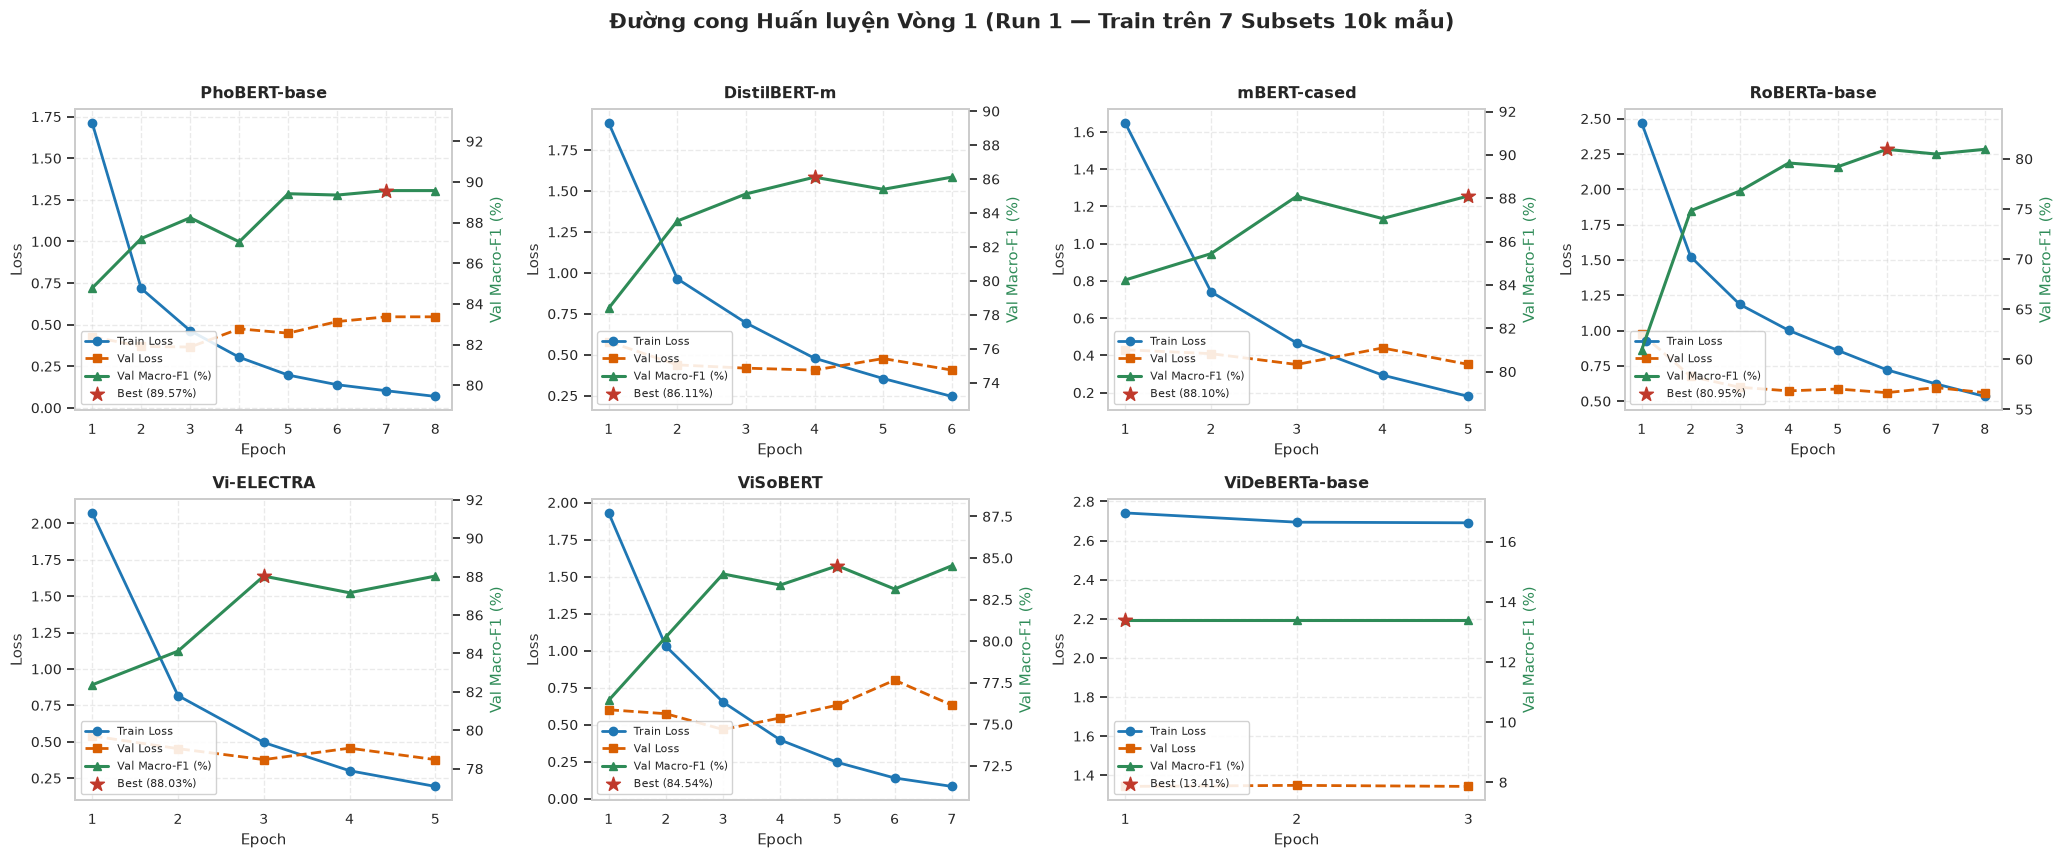

[Đã lưu biểu đồ] B3_01b_learning_curves_baseline.png, B3_01b_learning_curves_baseline.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B3_baseline_run1


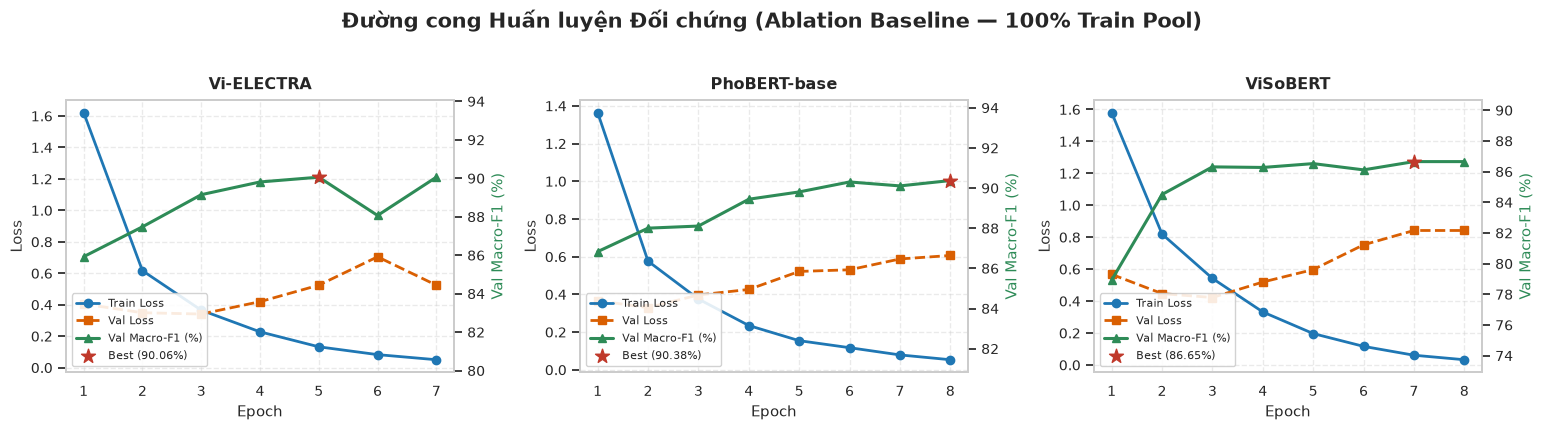

In [6]:
# Bước 3.6 — Biểu đồ B3.1: Learning Curves (Train Loss, Val Loss & Val Macro-F1 theo Epoch)
run1_histories = {}
for spec in cfg.get_active_models():
    hist_path = METRICS_DIR / f"run1_{spec.short_name}_history.csv"
    if hist_path.exists():
        run1_histories[spec.display_name] = pd.read_csv(hist_path)

if run1_histories:
    fig_lc_r1 = plot_learning_curves_grid(
        histories=run1_histories,
        title="Đường cong Huấn luyện Vòng 1 (Run 1 — Train trên 7 Subsets 10k mẫu)",
        save_dir=FIG_DIR,
        filename_stem="B3_01_learning_curves_run1",
        dpi=cfg.figure_dpi,
        save_pdf=cfg.save_pdf_figures,
    )
    plt.show()

# Vẽ thêm Learning Curves cho nhóm Ablation Baseline nếu có chạy
baseline_histories = {}
for spec in cfg.get_ablation_models():
    hist_path = METRICS_DIR / f"baseline_{spec.short_name}_history.csv"
    if hist_path.exists():
        baseline_histories[spec.display_name] = pd.read_csv(hist_path)

if baseline_histories:
    fig_lc_base = plot_learning_curves_grid(
        histories=baseline_histories,
        title="Đường cong Huấn luyện Đối chứng (Ablation Baseline — 100% Train Pool)",
        save_dir=FIG_DIR,
        filename_stem="B3_01b_learning_curves_baseline",
        dpi=cfg.figure_dpi,
        save_pdf=cfg.save_pdf_figures,
    )
    plt.show()

[Đã lưu biểu đồ] B3_02_so_sanh_hieu_nang_run1.png, B3_02_so_sanh_hieu_nang_run1.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B3_baseline_run1


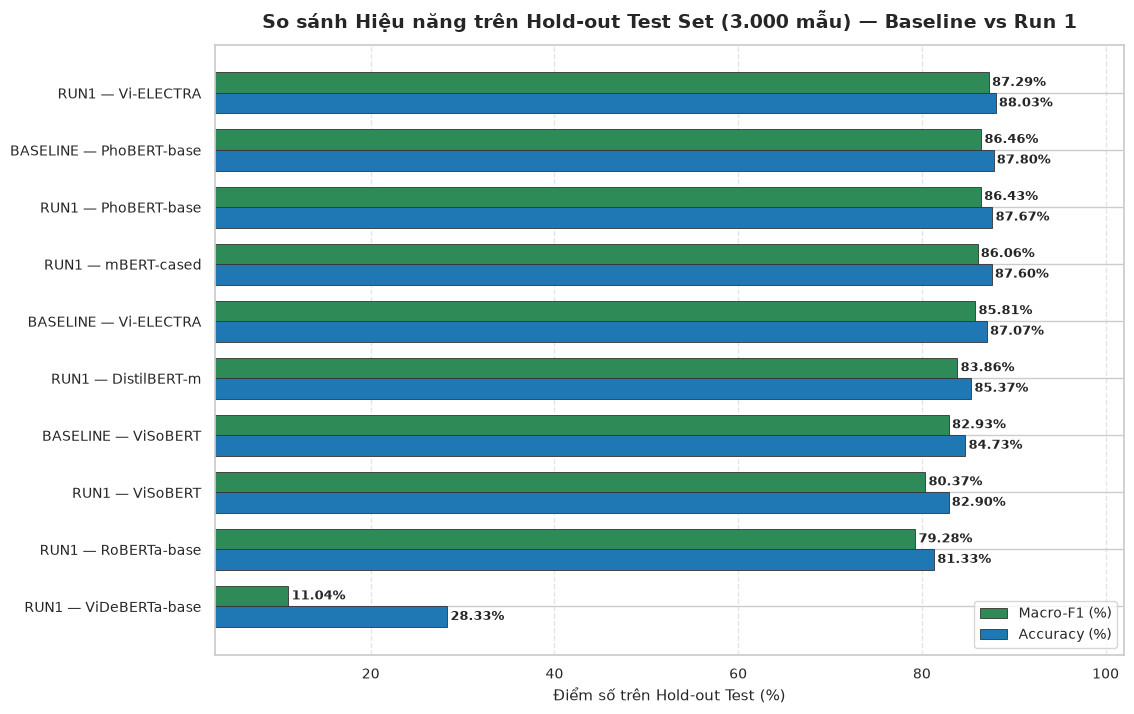


=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B3_baseline_run1 ===
  - B3_01_learning_curves_run1.pdf
  - B3_01_learning_curves_run1.png
  - B3_01b_learning_curves_baseline.pdf
  - B3_01b_learning_curves_baseline.png
  - B3_02_so_sanh_hieu_nang_run1.pdf
  - B3_02_so_sanh_hieu_nang_run1.png


In [7]:
# Bước 3.7 — Biểu đồ B3.2: So sánh Hiệu năng Hold-out Test Set (Ablation Baseline vs Run 1)
if not b3_summary_df.empty:
    fig_bench = plot_run_benchmark_comparison(
        summary_df=b3_summary_df,
        title="So sánh Hiệu năng trên Hold-out Test Set (3.000 mẫu) — Baseline vs Run 1",
        save_dir=FIG_DIR,
        filename_stem="B3_02_so_sanh_hieu_nang_run1",
        dpi=cfg.figure_dpi,
        save_pdf=cfg.save_pdf_figures,
    )
    plt.show()

print("\n=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B3_baseline_run1 ===")
for p in sorted(FIG_DIR.glob("*")):
    print(f"  - {p.name}")